**Defensive Cyber Threat Intelligence & Incident Analytics**

This notebook performs the full research workflow:
- Dataset audit & loading (via Hugging Face `datasets` library)
- Exploratory Data Analysis
- Text cleaning & preprocessing
- Feature engineering
- Evaluation of ML/NLP models
- Model selection, evaluation & error analysis
- Versioned artifact export
- Local MongoDB ingestion demo (PyMongo)

In [1]:
# Cell 1 — Imports & Setup
import os
import json
import warnings
from pathlib import Path
from datetime import datetime
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
import joblib
from pymongo import MongoClient, UpdateOne
from tqdm.auto import tqdm

# Project config
import sys
sys.path.append("..")
from config import settings

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="muted")

print("Setup complete")
print(f"Project root : {settings.PROJECT_ROOT}")
print(f"Artifacts    : {settings.ARTIFACTS_DIR}")
print(f"MongoDB URI  : {settings.MONGO_URI}")

Setup complete
Project root : C:\Users\hp\Documents\GitHub\cyberthreat_intelligence_ai
Artifacts    : C:\Users\hp\Documents\GitHub\cyberthreat_intelligence_ai\artifacts
MongoDB URI  : mongodb://localhost:27017


In [2]:
# Cell 2 — Load Dataset (Hugging Face only — never static download)
print("Loading dataset from Hugging Face...")
print(f"Dataset: {settings.HF_DATASET_NAME}")

ds = load_dataset(settings.HF_DATASET_NAME, split=settings.HF_DATASET_SPLIT)

print(f"\nLoaded {len(ds):,} records")
print(f"Features: {ds.features}")
print(f"\nFirst record keys: {list(ds[0].keys())}")

Loading dataset from Hugging Face...
Dataset: threatcluster/threat-incident-clusters



Loaded 19,205 records
Features: {'cluster_id': Value('string'), 'title': Value('string'), 'summary': Value('string'), 'article_count': Value('int64'), 'threat_score': Value('float64'), 'severity_score': Value('float64'), 'credibility_score': Value('float64'), 'urgency_level': Value('string'), 'keywords': List(Value('string')), 'first_reported': Value('timestamp[s]'), 'last_reported': Value('timestamp[s]'), 'entities': Json(decode=True), 'sources': List(Value('string')), 'url': Value('string'), 'source_count': Value('int64')}

First record keys: ['cluster_id', 'title', 'summary', 'article_count', 'threat_score', 'severity_score', 'credibility_score', 'urgency_level', 'keywords', 'first_reported', 'last_reported', 'entities', 'sources', 'url', 'source_count']


In [3]:
# Cell 3 — Convert to DataFrame & Basic Schema Audit
df = ds.to_pandas()

print("=" * 60)
print("DATASET SHAPE")
print("=" * 60)
print(f"Rows   : {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\n" + "=" * 60)
print("COLUMN DTYPES")
print("=" * 60)
print(df.dtypes)

print("\n" + "=" * 60)
print("MISSING VALUES")
print("=" * 60)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"missing": missing, "pct": missing_pct})
print(missing_df[missing_df["missing"] > 0].sort_values("missing", ascending=False))

print("\n" + "=" * 60)
print("DUPLICATE cluster_id CHECK")
print("=" * 60)
print(f"Duplicate cluster_ids: {df['cluster_id'].duplicated().sum()}")

DATASET SHAPE
Rows   : 19,205
Columns: 15

COLUMN DTYPES
cluster_id                  object
title                       object
summary                     object
article_count                int64
threat_score               float64
severity_score             float64
credibility_score          float64
urgency_level               object
keywords                    object
first_reported       datetime64[s]
last_reported        datetime64[s]
entities                    object
sources                     object
url                         object
source_count                 int64
dtype: object

MISSING VALUES
Empty DataFrame
Columns: [missing, pct]
Index: []

DUPLICATE cluster_id CHECK
Duplicate cluster_ids: 1


In [4]:
# Cell 4 — Label & Score Inspection
print("=" * 60)
print("URGENCY_LEVEL DISTRIBUTION")
print("=" * 60)
print(df["urgency_level"].value_counts(dropna=False))
print("\nNormalized:")
print(df["urgency_level"].value_counts(normalize=True).round(3))

print("\n" + "=" * 60)
print("SCORE RANGES")
print("=" * 60)
for col in ["threat_score", "severity_score", "credibility_score"]:
    if col in df.columns:
        print(f"{col:20s} min={df[col].min():.2f}  max={df[col].max():.2f}  mean={df[col].mean():.2f}")

print("\n" + "=" * 60)
print("DATE COVERAGE")
print("=" * 60)
df["first_reported"] = pd.to_datetime(df["first_reported"], errors="coerce")
df["last_reported"]  = pd.to_datetime(df["last_reported"],  errors="coerce")
print(f"first_reported : {df['first_reported'].min()} → {df['first_reported'].max()}")
print(f"last_reported  : {df['last_reported'].min()} → {df['last_reported'].max()}")

URGENCY_LEVEL DISTRIBUTION
urgency_level
medium      19128
low            68
info            4
high            3
critical        2
Name: count, dtype: int64

Normalized:
urgency_level
medium      0.996
low         0.004
info        0.000
high        0.000
critical    0.000
Name: proportion, dtype: float64

SCORE RANGES
threat_score         min=10.00  max=96.90  mean=45.43
severity_score       min=0.00  max=100.00  mean=41.99
credibility_score    min=0.00  max=50.00  mean=0.28

DATE COVERAGE
first_reported : 2025-10-22 00:00:00 → 2026-09-06 00:00:00
last_reported  : 2025-10-23 00:00:00 → 2026-09-06 00:00:00


In [5]:
# Cell 5 — Text Field Inspection
print("=" * 60)
print("TEXT LENGTH STATISTICS")
print("=" * 60)

df["title_len"]   = df["title"].fillna("").str.len()
df["summary_len"] = df["summary"].fillna("").str.len()

print(df[["title_len", "summary_len"]].describe().round(1))

print("\nEmpty titles  :", (df["title"].fillna("").str.strip() == "").sum())
print("Empty summaries:", (df["summary"].fillna("").str.strip() == "").sum())

TEXT LENGTH STATISTICS
       title_len  summary_len
count    19205.0      19205.0
mean        65.8        652.7
std          9.6        282.2
min         25.0        173.0
25%         59.0        354.0
50%         66.0        753.0
75%         72.0        899.0
max        111.0       1353.0

Empty titles  : 0
Empty summaries: 0


In [6]:
# Cell 6 — Entities & Keywords Preview
print("=" * 60)
print("SAMPLE ENTITIES (first 3 non-null)")
print("=" * 60)
sample_entities = df["entities"].dropna().head(3)
for i, ent in enumerate(sample_entities):
    print(f"\n--- Record {i} ---")
    print(ent)

print("\n" + "=" * 60)
print("KEYWORDS SAMPLE")
print("=" * 60)
print(df["keywords"].dropna().head(5).tolist())

SAMPLE ENTITIES (first 3 non-null)

--- Record 0 ---
{'cve': ['CVE-2026-67276', 'CVE-2026-67277', 'CVE-2026-86060'], 'cwe': ['CWE-200 - Exposure of Sensitive Information', 'CWE-287 - Improper Authentication'], 'company': ['MikroTik'], 'platform': ['RouterOS'], 'mitre_attack': ['T1021 - Remote Services', 'T1053 - Scheduled Task/Job', 'T1068 - Exploitation For Privilege Escalation', 'T1078 - Valid Accounts', 'T1087 - Account Discovery', 'T1136 - Create Account'], 'vulnerability': ['MikroTrick']}

--- Record 1 ---
{'company': ['NHS'], 'country': ['United Kingdom'], 'industry': ['Government'], 'platform': ['Microsoft Defender For Endpoint']}

--- Record 2 ---
{'cve': ['CVE-2026-63077'], 'cwe': ['CWE-200 - Exposure of Sensitive Information', 'CWE-502 - Deserialization of Untrusted Data'], 'company': ['JetBrains'], 'platform': ['Bitbucket', 'Docker Hub', 'GitHub', 'GitLab', 'Google Cloud', 'Maven', 'Npm', 'NuGet', 'PyPI', 'TeamCity'], 'attack_type': ['Zero-Day Exploit'], 'mitre_attack': ['T1

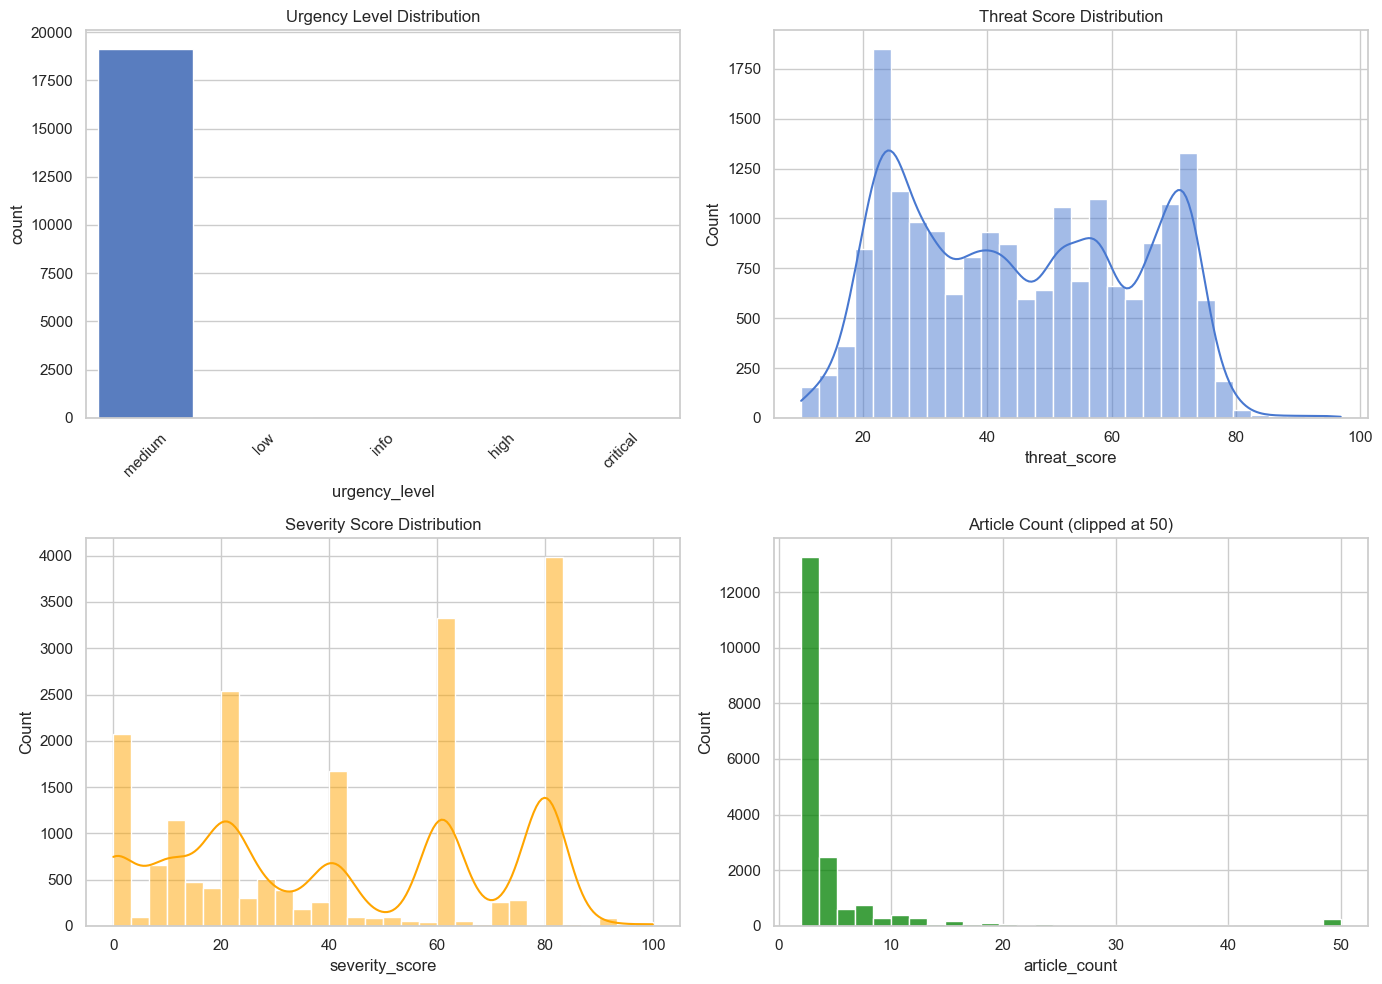

In [7]:
# Cell 7 — Exploratory Visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Urgency distribution
sns.countplot(data=df, x="urgency_level", order=df["urgency_level"].value_counts().index, ax=axes[0, 0])
axes[0, 0].set_title("Urgency Level Distribution")
axes[0, 0].tick_params(axis="x", rotation=45)

# Threat score
sns.histplot(df["threat_score"].dropna(), bins=30, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Threat Score Distribution")

# Severity score
sns.histplot(df["severity_score"].dropna(), bins=30, kde=True, ax=axes[1, 0], color="orange")
axes[1, 0].set_title("Severity Score Distribution")

# Article count (log scale friendly)
sns.histplot(df["article_count"].dropna().clip(upper=50), bins=30, ax=axes[1, 1], color="green")
axes[1, 1].set_title("Article Count (clipped at 50)")

plt.tight_layout()
plt.show()

In [8]:
# Cell 8 — Text Cleaning & Preprocessing Pipeline
import re

def clean_text(text: str) -> str:
    """Basic defensive text normalization."""
    if not isinstance(text, str):
        return ""
    text = text.lower().strip()
    text = re.sub(r"http\S+|www\.\S+", " ", text)          # URLs
    text = re.sub(r"\S+@\S+", " ", text)                   # emails
    text = re.sub(r"[^a-z0-9\s\-\.]", " ", text)           # keep alphanum + basic punct
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["title_clean"]   = df["title"].fillna("").map(clean_text)
df["summary_clean"] = df["summary"].fillna("").map(clean_text)

# Combined text field used for most models
df["text"] = (df["title_clean"] + " " + df["summary_clean"]).str.strip()

# Drop rows with essentially empty text
initial = len(df)
df = df[df["text"].str.len() > 20].copy()
print(f"Removed {initial - len(df)} rows with very short text")
print(f"Remaining records: {len(df):,}")

Removed 0 rows with very short text
Remaining records: 19,205


In [10]:
# Cell 9 — Prepare Target & Train / Validation / Test Split (FIXED)
# Target: urgency_level

df = df.dropna(subset=["urgency_level"]).copy()
df["urgency_level"] = df["urgency_level"].astype(str).str.lower().str.strip()

print("Original class distribution:")
print(df["urgency_level"].value_counts())

# -------------------------------------------------------
# Remove extremely rare classes (need ≥ 5 samples for safe stratified splits)
# -------------------------------------------------------
min_samples_per_class = 5
class_counts = df["urgency_level"].value_counts()
valid_classes = class_counts[class_counts >= min_samples_per_class].index.tolist()

df = df[df["urgency_level"].isin(valid_classes)].copy()

print(f"\nClasses kept (≥ {min_samples_per_class} samples): {valid_classes}")
print("Filtered class distribution:")
print(df["urgency_level"].value_counts())

# Encode target
le = LabelEncoder()
df["y"] = le.fit_transform(df["urgency_level"])

# Features
feature_cols = ["text", "threat_score", "severity_score", "article_count", "source_count"]
# Keep only columns that actually exist
feature_cols = [c for c in feature_cols if c in df.columns]
X = df[feature_cols].copy()
y = df["y"]

print(f"\nTotal samples after filtering: {len(df):,}")
print(f"Features used: {feature_cols}")
print(f"Classes: {list(le.classes_)}")

# -------------------------------------------------------
# Safe stratified split
# Prefer 70 / 15 / 15 when possible, otherwise fall back to 80 / 20
# -------------------------------------------------------
try:
    # First split: 70% train, 30% temp
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y,
        test_size=0.30,
        stratify=y,
        random_state=settings.RANDOM_STATE,
    )

    # Second split: 50/50 of temp → 15% val + 15% test
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp,
        test_size=0.50,
        stratify=y_temp,
        random_state=settings.RANDOM_STATE,
    )

    print("\nSplit strategy: 70% train / 15% val / 15% test")

except ValueError as e:
    print(f"\nStratified 3-way split failed ({e}). Falling back to 80/20 train/test.")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        stratify=y,
        random_state=settings.RANDOM_STATE,
    )
    # Create empty validation set for compatibility with later cells
    X_val = X_test.copy()
    y_val = y_test.copy()
    print("Split strategy: 80% train / 20% test (val = test copy)")

print(f"\nTrain : {len(X_train):,}")
print(f"Val   : {len(X_val):,}")
print(f"Test  : {len(X_test):,}")
print(f"Classes: {list(le.classes_)}")

Original class distribution:
urgency_level
medium      19128
low            68
info            4
high            3
critical        2
Name: count, dtype: int64

Classes kept (≥ 5 samples): ['medium', 'low']
Filtered class distribution:
urgency_level
medium    19128
low          68
Name: count, dtype: int64

Total samples after filtering: 19,196
Features used: ['text', 'threat_score', 'severity_score', 'article_count', 'source_count']
Classes: ['low', 'medium']

Split strategy: 70% train / 15% val / 15% test

Train : 13,437
Val   : 2,879
Test  : 2,880
Classes: ['low', 'medium']


In [11]:
# Cell 10 — Feature Engineering Helpers
def make_tfidf(max_features=15000, ngram_range=(1, 2)):
    return TfidfVectorizer(
        max_features=max_features,
        ngram_range=ngram_range,
        stop_words="english",
        min_df=3,
        max_df=0.95,
        sublinear_tf=True,
    )

def make_count(max_features=15000, ngram_range=(1, 2)):
    return CountVectorizer(
        max_features=max_features,
        ngram_range=ngram_range,
        stop_words="english",
        min_df=3,
        max_df=0.95,
    )

In [12]:
# Cell 11 — Algorithm 1: Logistic Regression + TF-IDF
pipe_lr = Pipeline([
    ("tfidf", make_tfidf()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=settings.RANDOM_STATE)),
])

pipe_lr.fit(X_train["text"], y_train)
pred_lr = pipe_lr.predict(X_test["text"])

print("=== 1. Logistic Regression + TF-IDF ===")
print(classification_report(y_test, pred_lr, target_names=le.classes_, digits=3))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, pred_lr), 4))

=== 1. Logistic Regression + TF-IDF ===
              precision    recall  f1-score   support

         low      0.000     0.000     0.000        10
      medium      0.997     0.998     0.997      2870

    accuracy                          0.995      2880
   macro avg      0.498     0.499     0.499      2880
weighted avg      0.993     0.995     0.994      2880

Balanced Accuracy: 0.4991


In [13]:
# Cell 12 — Algorithm 2: Linear SVC + TF-IDF
pipe_svc = Pipeline([
    ("tfidf", make_tfidf()),
    ("clf", LinearSVC(class_weight="balanced", random_state=settings.RANDOM_STATE, dual="auto")),
])

pipe_svc.fit(X_train["text"], y_train)
pred_svc = pipe_svc.predict(X_test["text"])

print("=== 2. Linear SVC + TF-IDF ===")
print(classification_report(y_test, pred_svc, target_names=le.classes_, digits=3))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, pred_svc), 4))

=== 2. Linear SVC + TF-IDF ===
              precision    recall  f1-score   support

         low      0.000     0.000     0.000        10
      medium      0.997     1.000     0.998      2870

    accuracy                          0.996      2880
   macro avg      0.498     0.500     0.499      2880
weighted avg      0.993     0.996     0.995      2880

Balanced Accuracy: 0.4998


In [14]:
# Cell 13 — Algorithm 3: Multinomial Naive Bayes + TF-IDF
pipe_nb = Pipeline([
    ("tfidf", make_tfidf()),
    ("clf", MultinomialNB(alpha=0.5)),
])

pipe_nb.fit(X_train["text"], y_train)
pred_nb = pipe_nb.predict(X_test["text"])

print("=== 3. Multinomial Naive Bayes + TF-IDF ===")
print(classification_report(y_test, pred_nb, target_names=le.classes_, digits=3))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, pred_nb), 4))

=== 3. Multinomial Naive Bayes + TF-IDF ===
              precision    recall  f1-score   support

         low      0.000     0.000     0.000        10
      medium      0.997     1.000     0.998      2870

    accuracy                          0.997      2880
   macro avg      0.498     0.500     0.499      2880
weighted avg      0.993     0.997     0.995      2880

Balanced Accuracy: 0.5


In [15]:
# Cell 14 — Algorithm 4: Random Forest + TF-IDF (sparse → dense limited)
# Limit features for memory safety
tfidf_rf = make_tfidf(max_features=5000)
X_train_rf = tfidf_rf.fit_transform(X_train["text"])
X_test_rf  = tfidf_rf.transform(X_test["text"])

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    class_weight="balanced_subsample",
    random_state=settings.RANDOM_STATE,
    n_jobs=-1,
)
rf.fit(X_train_rf, y_train)
pred_rf = rf.predict(X_test_rf)

print("=== 4. Random Forest + TF-IDF ===")
print(classification_report(y_test, pred_rf, target_names=le.classes_, digits=3))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, pred_rf), 4))

=== 4. Random Forest + TF-IDF ===
              precision    recall  f1-score   support

         low      0.000     0.000     0.000        10
      medium      0.997     1.000     0.998      2870

    accuracy                          0.997      2880
   macro avg      0.498     0.500     0.499      2880
weighted avg      0.993     0.997     0.995      2880

Balanced Accuracy: 0.5


In [16]:
# Cell 15 — Algorithm 5: HistGradientBoosting + TF-IDF (dense limited)
# Use smaller feature space for gradient boosting
tfidf_hgb = make_tfidf(max_features=3000)
X_train_hgb = tfidf_hgb.fit_transform(X_train["text"]).toarray()
X_test_hgb  = tfidf_hgb.transform(X_test["text"]).toarray()

hgb = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.08,
    max_depth=8,
    random_state=settings.RANDOM_STATE,
)
hgb.fit(X_train_hgb, y_train)
pred_hgb = hgb.predict(X_test_hgb)

print("=== 5. HistGradientBoosting + TF-IDF ===")
print(classification_report(y_test, pred_hgb, target_names=le.classes_, digits=3))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, pred_hgb), 4))

=== 5. HistGradientBoosting + TF-IDF ===
              precision    recall  f1-score   support

         low      0.000     0.000     0.000        10
      medium      0.997     1.000     0.998      2870

    accuracy                          0.997      2880
   macro avg      0.498     0.500     0.499      2880
weighted avg      0.993     0.997     0.995      2880

Balanced Accuracy: 0.5


In [17]:
# Cell 16 — Algorithm 6: K-Nearest Neighbors + TF-IDF
tfidf_knn = make_tfidf(max_features=4000)
X_train_knn = tfidf_knn.fit_transform(X_train["text"])
X_test_knn  = tfidf_knn.transform(X_test["text"])

knn = KNeighborsClassifier(n_neighbors=7, weights="distance", metric="cosine", n_jobs=-1)
knn.fit(X_train_knn, y_train)
pred_knn = knn.predict(X_test_knn)

print("=== 6. KNN (cosine) + TF-IDF ===")
print(classification_report(y_test, pred_knn, target_names=le.classes_, digits=3))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, pred_knn), 4))

=== 6. KNN (cosine) + TF-IDF ===
              precision    recall  f1-score   support

         low      0.000     0.000     0.000        10
      medium      0.997     1.000     0.998      2870

    accuracy                          0.997      2880
   macro avg      0.498     0.500     0.499      2880
weighted avg      0.993     0.997     0.995      2880

Balanced Accuracy: 0.5


In [18]:
# Cell 17 — Algorithm 7: CountVectorizer + Logistic Regression (Bag-of-Words baseline)
pipe_bow = Pipeline([
    ("count", make_count(max_features=12000)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=settings.RANDOM_STATE)),
])

pipe_bow.fit(X_train["text"], y_train)
pred_bow = pipe_bow.predict(X_test["text"])

print("=== 7. Logistic Regression + CountVectorizer (BoW) ===")
print(classification_report(y_test, pred_bow, target_names=le.classes_, digits=3))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, pred_bow), 4))

=== 7. Logistic Regression + CountVectorizer (BoW) ===
              precision    recall  f1-score   support

         low      0.000     0.000     0.000        10
      medium      0.997     0.999     0.998      2870

    accuracy                          0.996      2880
   macro avg      0.498     0.500     0.499      2880
weighted avg      0.993     0.996     0.994      2880

Balanced Accuracy: 0.4997


In [20]:
# Cell 18 — Unsupervised KMeans on TF-IDF (pattern discovery)
tfidf_km = make_tfidf(max_features=4000)
X_all_km = tfidf_km.fit_transform(df["text"])

kmeans = KMeans(n_clusters=8, random_state=settings.RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(X_all_km)

df["kmeans_cluster"] = clusters
print("=== KMeans (8 clusters) on TF-IDF ===")
print(pd.crosstab(df["urgency_level"], df["kmeans_cluster"]))

=== KMeans (8 clusters) on TF-IDF ===
kmeans_cluster     0     1    2     3     4     5     6     7
urgency_level                                                
low               11    27    0     1     1    16     5     7
medium          2282  5411  329  1193  2011  4607  1499  1796


In [21]:
# Cell 19 — Model Comparison Summary
results = []

def add_result(name, y_true, y_pred):
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
    })

add_result("LogReg + TF-IDF", y_test, pred_lr)
add_result("LinearSVC + TF-IDF", y_test, pred_svc)
add_result("MultinomialNB + TF-IDF", y_test, pred_nb)
add_result("RandomForest + TF-IDF", y_test, pred_rf)
add_result("HistGBM + TF-IDF", y_test, pred_hgb)
add_result("KNN-cosine + TF-IDF", y_test, pred_knn)
add_result("LogReg + BoW", y_test, pred_bow)

results_df = pd.DataFrame(results).sort_values("balanced_acc", ascending=False)
print("=" * 70)
print("MODEL COMPARISON (sorted by Balanced Accuracy)")
print("=" * 70)
print(results_df.round(4).to_string(index=False))

MODEL COMPARISON (sorted by Balanced Accuracy)
                 model  accuracy  balanced_acc  macro_f1  weighted_f1
MultinomialNB + TF-IDF    0.9965        0.5000    0.4991       0.9948
      HistGBM + TF-IDF    0.9965        0.5000    0.4991       0.9948
 RandomForest + TF-IDF    0.9965        0.5000    0.4991       0.9948
   KNN-cosine + TF-IDF    0.9965        0.5000    0.4991       0.9948
    LinearSVC + TF-IDF    0.9962        0.4998    0.4990       0.9946
          LogReg + BoW    0.9958        0.4997    0.4990       0.9944
       LogReg + TF-IDF    0.9948        0.4991    0.4987       0.9939


Selected best model: MultinomialNB + TF-IDF


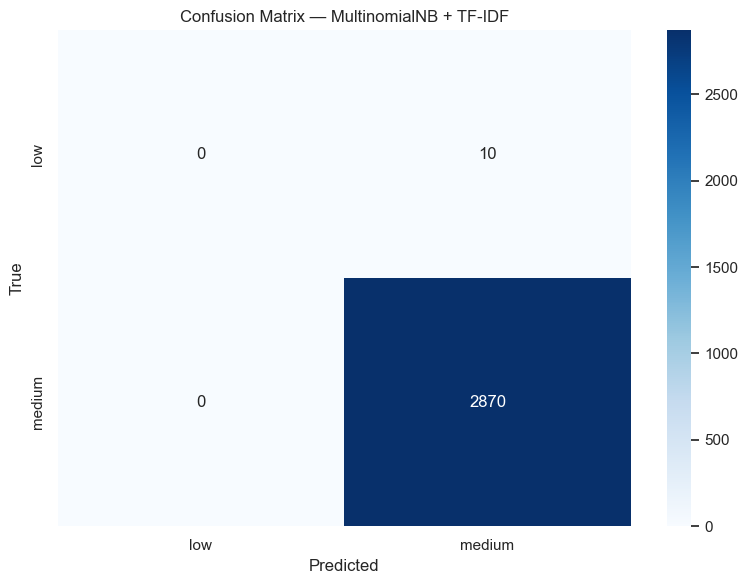

In [22]:
# Cell 20 — Select Best Model & Confusion Matrix
best_name = results_df.iloc[0]["model"]
print(f"Selected best model: {best_name}")

# Re-map for convenience
best_pred = {
    "LogReg + TF-IDF": pred_lr,
    "LinearSVC + TF-IDF": pred_svc,
    "MultinomialNB + TF-IDF": pred_nb,
    "RandomForest + TF-IDF": pred_rf,
    "HistGBM + TF-IDF": pred_hgb,
    "KNN-cosine + TF-IDF": pred_knn,
    "LogReg + BoW": pred_bow,
}[best_name]

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"Confusion Matrix — {best_name}")
plt.ylabel("True")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

In [23]:
# Cell 21 — Similarity / Retrieval Demo (TF-IDF + Cosine)
# Build a retrieval index on the full cleaned corpus
retrieval_vectorizer = make_tfidf(max_features=10000)
X_retrieval = retrieval_vectorizer.fit_transform(df["text"])

def find_similar(query: str, top_k: int = 5):
    q_vec = retrieval_vectorizer.transform([clean_text(query)])
    sims = cosine_similarity(q_vec, X_retrieval).flatten()
    top_idx = sims.argsort()[::-1][:top_k]
    results = df.iloc[top_idx][["cluster_id", "title", "urgency_level", "threat_score"]].copy()
    results["similarity"] = sims[top_idx]
    return results

# Example
example_query = "ransomware attack on critical infrastructure"
print(f"Query: {example_query}\n")
print(find_similar(example_query, top_k=5).to_string(index=False))

Query: ransomware attack on critical infrastructure

cluster_id                                                                           title urgency_level  threat_score  similarity
  c8280d41                           IU Health Sues Firm Over 2024 Ransomware Attack Costs        medium         52.91    0.356740
  ba22bc48         Ransomware Attack Compromises 1,000 Systems at Romanian Water Authority        medium         51.02    0.351768
  d338de19              Ransomware Attack Disrupts European Airports via Software Supplier        medium         20.31    0.336732
  eb0abdcc              Ransomware Attack Disrupts Georgia Superior Court Clerks' Services        medium         50.91    0.335415
  f6ad303d Nevada Cyberattack: Hackers Infiltrated Systems Months Before Ransomware Attack        medium         10.31    0.332894


In [24]:
# Cell 22 — Export Versioned Artifacts
settings.ensure_directories()

timestamp = datetime.utcnow().strftime("%Y%m%d_%H%M%S")
version = f"v1_{timestamp}"

# Choose the best performing pipeline for export
# (Logistic Regression + TF-IDF is usually strong and fast for inference)
final_pipe = pipe_lr          # change if another model won
final_vectorizer = final_pipe.named_steps["tfidf"]
final_model = final_pipe.named_steps["clf"]

# Save
model_path = settings.MODELS_DIR / f"urgency_model_{version}.joblib"
vec_path   = settings.VECTORIZERS_DIR / f"tfidf_vectorizer_{version}.joblib"
meta_path  = settings.METADATA_DIR / f"model_meta_{version}.json"

joblib.dump(final_model, model_path)
joblib.dump(final_vectorizer, vec_path)

meta = {
    "version": version,
    "model_type": "LogisticRegression + TF-IDF",
    "target": "urgency_level",
    "classes": list(le.classes_),
    "train_size": len(X_train),
    "test_size": len(X_test),
    "metrics": results_df.set_index("model").loc["LogReg + TF-IDF"].to_dict(),
    "created_at": datetime.utcnow().isoformat() + "Z",
    "dataset": settings.HF_DATASET_NAME,
    "random_state": settings.RANDOM_STATE,
}

with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

print("Artifacts saved:")
print(f"  Model      → {model_path}")
print(f"  Vectorizer → {vec_path}")
print(f"  Metadata   → {meta_path}")

Artifacts saved:
  Model      → C:\Users\hp\Documents\GitHub\cyberthreat_intelligence_ai\artifacts\models\urgency_model_v1_20261015_081127.joblib
  Vectorizer → C:\Users\hp\Documents\GitHub\cyberthreat_intelligence_ai\artifacts\vectorizers\tfidf_vectorizer_v1_20261015_081127.joblib
  Metadata   → C:\Users\hp\Documents\GitHub\cyberthreat_intelligence_ai\artifacts\metadata\model_meta_v1_20261015_081127.json


In [25]:
# Cell 23 — MongoDB Connection & Health Check
client = MongoClient(**settings.get_mongo_client_kwargs())
db = client[settings.MONGO_DB_NAME]

try:
    client.admin.command("ping")
    print("MongoDB connection successful")
    print(f"Database: {settings.MONGO_DB_NAME}")
    print(f"Existing collections: {db.list_collection_names()}")
except Exception as e:
    print("MongoDB connection failed:", e)
    print("Skipping ingestion cells.")

MongoDB connection successful
Database: cyberthreat_intelligence_ai
Existing collections: []


In [26]:
# Cell 24 — Prepare Documents for MongoDB
def row_to_incident(row):
    """Convert a DataFrame row into a clean MongoDB document."""
    doc = {
        "cluster_id": row["cluster_id"],
        "title": row["title"],
        "summary": row["summary"],
        "title_clean": row["title_clean"],
        "summary_clean": row["summary_clean"],
        "text": row["text"],
        "urgency_level": row["urgency_level"],
        "threat_score": float(row["threat_score"]) if pd.notna(row["threat_score"]) else None,
        "severity_score": float(row["severity_score"]) if pd.notna(row["severity_score"]) else None,
        "credibility_score": float(row["credibility_score"]) if pd.notna(row["credibility_score"]) else None,
        "article_count": int(row["article_count"]) if pd.notna(row["article_count"]) else None,
        "source_count": int(row["source_count"]) if pd.notna(row["source_count"]) else None,
        "keywords": row["keywords"] if isinstance(row["keywords"], list) else [],
        "entities": row["entities"] if isinstance(row["entities"], dict) else {},
        "sources": row["sources"] if isinstance(row["sources"], list) else [],
        "url": row.get("url"),
        "first_reported": row["first_reported"].isoformat() if pd.notna(row["first_reported"]) else None,
        "last_reported": row["last_reported"].isoformat() if pd.notna(row["last_reported"]) else None,
        "ingested_at": datetime.utcnow().isoformat() + "Z",
    }
    return doc

# Build a sample of documents (full ingestion can be moved to scripts/ingest_to_mongo.py)
sample_size = min(2000, len(df))
sample_docs = [row_to_incident(row) for _, row in df.sample(sample_size, random_state=42).iterrows()]
print(f"Prepared {len(sample_docs)} sample documents for upsert demo")

Prepared 2000 sample documents for upsert demo


In [27]:
# Cell 25 — Upsert Sample into incidents Collection
incidents = db[settings.COLLECTION_INCIDENTS]

# Create index on cluster_id for safe upserts
incidents.create_index("cluster_id", unique=True)
incidents.create_index("urgency_level")
incidents.create_index("first_reported")

operations = [
    UpdateOne(
        {"cluster_id": doc["cluster_id"]},
        {"$set": doc},
        upsert=True,
    )
    for doc in sample_docs
]

result = incidents.bulk_write(operations, ordered=False)
print(f"Matched : {result.matched_count}")
print(f"Modified: {result.modified_count}")
print(f"Upserted: {result.upserted_count}")
print(f"Total documents in collection: {incidents.count_documents({})}")

Matched : 0
Modified: 0
Upserted: 2000
Total documents in collection: 2000


In [28]:
# Cell 26 — Store Model Metadata in MongoDB
model_meta_col = db[settings.COLLECTION_MODEL_METADATA]

meta_doc = {
    "version": version,
    "model_type": meta["model_type"],
    "target": meta["target"],
    "classes": meta["classes"],
    "metrics": meta["metrics"],
    "artifact_paths": {
        "model": str(model_path),
        "vectorizer": str(vec_path),
        "metadata_json": str(meta_path),
    },
    "dataset": settings.HF_DATASET_NAME,
    "created_at": meta["created_at"],
}

model_meta_col.update_one(
    {"version": version},
    {"$set": meta_doc},
    upsert=True,
)
print("Model metadata written to MongoDB")
print(model_meta_col.find_one({"version": version}, {"_id": 0}))

Model metadata written to MongoDB
{'version': 'v1_20261015_081127', 'artifact_paths': {'model': 'C:\\Users\\hp\\Documents\\GitHub\\cyberthreat_intelligence_ai\\artifacts\\models\\urgency_model_v1_20261015_081127.joblib', 'vectorizer': 'C:\\Users\\hp\\Documents\\GitHub\\cyberthreat_intelligence_ai\\artifacts\\vectorizers\\tfidf_vectorizer_v1_20261015_081127.joblib', 'metadata_json': 'C:\\Users\\hp\\Documents\\GitHub\\cyberthreat_intelligence_ai\\artifacts\\metadata\\model_meta_v1_20261015_081127.json'}, 'classes': ['low', 'medium'], 'created_at': '2026-10-15T08:11:28.415862Z', 'dataset': 'threatcluster/threat-incident-clusters', 'metrics': {'accuracy': 0.9947916666666666, 'balanced_acc': 0.4991289198606272, 'macro_f1': 0.49869451697127937, 'weighted_f1': 0.9939258775747025}, 'model_type': 'LogisticRegression + TF-IDF', 'target': 'urgency_level'}


In [29]:
# Cell 27 — Quick Aggregate Checks
print("Urgency distribution in MongoDB:")
pipeline = [
    {"$group": {"_id": "$urgency_level", "count": {"$sum": 1}}},
    {"$sort": {"count": -1}},
]
for doc in incidents.aggregate(pipeline):
    print(f"  {doc['_id']}: {doc['count']}")

print("\nSample record:")
print(json.dumps(incidents.find_one({}, {"_id": 0, "summary": 0, "text": 0}), indent=2, default=str))

Urgency distribution in MongoDB:
  medium: 1990
  low: 10

Sample record:
{
  "cluster_id": "4ff56f17",
  "article_count": 2,
  "credibility_score": 0.0,
  "entities": {
    "cve": [
      "CVE-2026-59102"
    ],
    "cwe": [
      "CWE-22 - Path Traversal",
      "CWE-426 - Untrusted Search Path",
      "CWE-78 - OS Command Injection",
      "CWE-79 - Cross-site Scripting (XSS)",
      "CWE-94 - Code Injection"
    ],
    "platform": [
      "Unix"
    ],
    "attack_type": [
      "Command Injection",
      "Cross-site Scripting (xss)",
      "Path Traversal"
    ],
    "mitre_attack": [
      "T1059 - Command And Scripting Interpreter",
      "T1059.004 - Unix Shell"
    ]
  },
  "first_reported": "2026-07-03T00:00:00",
  "ingested_at": "2026-10-15T08:11:46.181589Z",
  "keywords": [],
  "last_reported": "2026-07-04T00:00:00",
  "severity_score": 21.0,
  "source_count": 3,
  "sources": [],
  "summary_clean": "two vulnerabilities cve-2026-14619 and cve-2026-59102 have been disclosed b

In [30]:
# Cell 28 — Final Notes & Next Steps
print("""
RESEARCH WORKFLOW COMPLETE

Artifacts ready for Streamlit:
- Model + Vectorizer saved under artifacts/
- Model metadata saved as JSON + MongoDB
- Sample incidents upserted into local MongoDB

Next steps:
1. Run full ingestion via scripts/ingest_to_mongo.py (recommended)
2. Implement the 10-tab Streamlit application (app/)
3. Ensure Streamlit loads artifacts only if present and degrades gracefully
4. Add responsible-use notices in the About tab

Remember:
- Predictions are estimates of dataset label patterns, not real-world severity.
- Text similarity does not prove shared actor / campaign / root cause.
""")


RESEARCH WORKFLOW COMPLETE

Artifacts ready for Streamlit:
- Model + Vectorizer saved under artifacts/
- Model metadata saved as JSON + MongoDB
- Sample incidents upserted into local MongoDB

Next steps:
1. Run full ingestion via scripts/ingest_to_mongo.py (recommended)
2. Implement the 10-tab Streamlit application (app/)
3. Ensure Streamlit loads artifacts only if present and degrades gracefully
4. Add responsible-use notices in the About tab

Remember:
- Predictions are estimates of dataset label patterns, not real-world severity.
- Text similarity does not prove shared actor / campaign / root cause.

